# Nearest-Neighbor Object Recognition

This notebook goes with the lecture on nearest-neighbor object recognition. It recognizes people from small face photos by finding the most similar stored photo, measures what helps and what hurts (the distance, normalization, the number of PCA numbers, the number of neighbors), asks what happens when the face belongs to nobody in the database, and makes the search faster with PCA. The second half computes image moments by hand and with OpenCV, and uses Hu moments to recognize printed digits.

Data: `data/face_recongition_db` holds 10 people with 5 training photos and 1 test photo each; `data/faces` holds the 337 faces of the PCA lecture. The digits are drawn by the notebook itself with OpenCV's fonts, so nothing has to be downloaded.

In [1]:
import os
import time

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

## The Face Database

Each photo is cropped to the same 60 × 50 window around the face as in the PCA lecture and flattened into a vector of 3,000 numbers. The folder name is the person's label. `sorted` makes the order of the files the same on every computer (`os.listdir` returns them in whatever order the file system keeps them).

In [2]:
def load_faces(folder):
    vectors, labels = [], []
    for person in sorted(os.listdir(folder), key=int):
        for filename in sorted(os.listdir(os.path.join(folder, person))):
            if filename.endswith('.bmp'):
                img = cv.imread(os.path.join(folder, person, filename), cv.IMREAD_GRAYSCALE)
                img = img[25:85, 25:75]                 # crop the face: 60 x 50 pixels
                vectors.append(img.flatten())           # 3000 numbers
                labels.append(int(person))
    return np.array(vectors).astype(np.float32), np.array(labels)

train_data, train_labels = load_faces('data/face_recongition_db/train_data')
test_data, test_labels = load_faces('data/face_recongition_db/test_data')
print('training faces:', train_data.shape, ' labels:', train_labels)
print('test faces:    ', test_data.shape, ' labels:', test_labels)

training faces: (50, 3000)  labels: [0 0 0 0 0 1 1 1 1 1 2 2 2 2 2 3 3 3 3 3 4 4 4 4 4 5 5 5 5 5 6 6 6 6 6 7 7
 7 7 7 8 8 8 8 8 9 9 9 9 9]
test faces:     (10, 3000)  labels: [0 1 2 3 4 5 6 7 8 9]


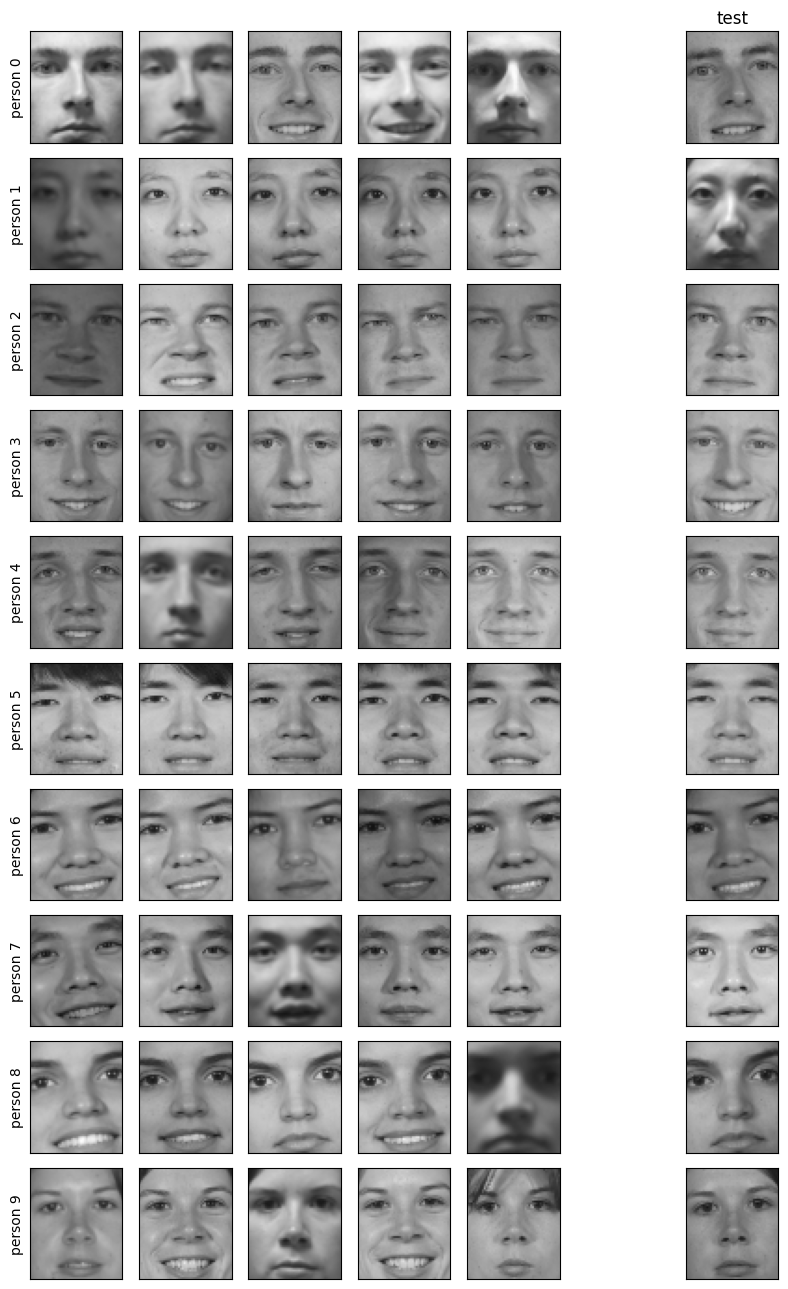

In [3]:
# Each row: the 5 training photos of one person, then (far right) that person's test photo
fig, axs = plt.subplots(10, 7, figsize=(8, 13))
for person in range(10):
    for k in range(5):
        axs[person, k].imshow(train_data[person * 5 + k].reshape(60, 50), cmap='gray', vmin=0, vmax=255)
    axs[person, 6].imshow(test_data[person].reshape(60, 50), cmap='gray', vmin=0, vmax=255)
    axs[person, 0].set_ylabel(f'person {person}')
axs[0, 6].set_title('test')
for ax in axs.flat:
    ax.set_xticks([]); ax.set_yticks([])
for ax in axs[:, 5]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Measuring Distance

The Euclidean (L2) distance between two images squares the pixel differences, adds them and takes the square root; the Manhattan (L1) distance adds the absolute differences. Here they are on two tiny 2 × 2 "images", by hand and with NumPy.

In [4]:
X = np.array([[10, 20],
              [30, 40]], dtype=np.float64)
Y = np.array([[12, 20],
              [25, 46]], dtype=np.float64)

print('differences:', (X - Y).flatten())
print('L2 by hand: ', np.sqrt(2**2 + 0**2 + 5**2 + 6**2))
print('L2:         ', np.sqrt(np.sum((X - Y)**2)), np.linalg.norm(X - Y))
print('L1:         ', np.sum(np.abs(X - Y)))
p = 3
print('L3:         ', np.sum(np.abs(X - Y)**p)**(1 / p))

differences: [-2.  0.  5. -6.]
L2 by hand:  8.06225774829855
L2:          8.06225774829855 8.06225774829855
L1:          13.0
L3:          7.040580616713472


**The `uint8` trap.** `cv.imread` returns `uint8` arrays, and subtracting two `uint8` arrays wraps around modulo 256 instead of going negative. The distance comes out as a believable number, and it is wrong. Convert to a float type first, or let `cv.norm` do the arithmetic in double precision.

In [5]:
a = np.array([[100]], dtype=np.uint8)
b = np.array([[200]], dtype=np.uint8)
print('a - b as uint8:          ', a - b)
print('np.linalg.norm(a - b):   ', np.linalg.norm(a - b), '  <- wrong')
print('after astype(np.float64):', np.linalg.norm(a.astype(np.float64) - b))
print('cv.norm(a, b, NORM_L2):  ', cv.norm(a, b, cv.NORM_L2))

a - b as uint8:           [[156]]
np.linalg.norm(a - b):    156.0   <- wrong
after astype(np.float64): 100.0
cv.norm(a, b, NORM_L2):   100.0


## 1-Nearest Neighbor on Raw Pixels

Training is just storing the 50 labeled faces. To recognize a test face, compute its distance to every stored face and return the label of the closest one.

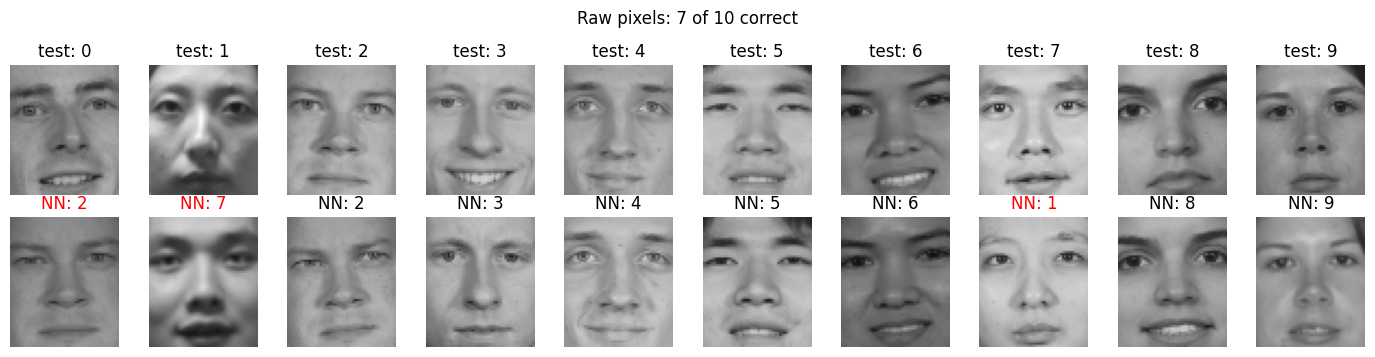

np.int64(7)

In [6]:
def nearest_neighbor(train_vectors, labels, query):
    distances = np.linalg.norm(train_vectors - query, axis=1)   # one distance per stored face
    best = np.argmin(distances)
    return labels[best], best, distances[best]

def show_matches(train_vectors, test_vectors, title):
    correct = 0
    fig, axs = plt.subplots(2, 10, figsize=(14, 3.6))
    for i in range(len(test_vectors)):
        label, best, dist = nearest_neighbor(train_vectors, train_labels, test_vectors[i])
        correct += label == test_labels[i]
        axs[0, i].imshow(test_data[i].reshape(60, 50), cmap='gray', vmin=0, vmax=255)
        axs[0, i].set_title(f'test: {test_labels[i]}')
        axs[1, i].imshow(train_data[best].reshape(60, 50), cmap='gray', vmin=0, vmax=255)
        axs[1, i].set_title(f'NN: {label}', color='black' if label == test_labels[i] else 'red')
    for ax in axs.flat:
        ax.axis('off')
    fig.suptitle(f'{title}: {correct} of {len(test_vectors)} correct')
    plt.tight_layout()
    plt.show()
    return correct

show_matches(train_data, test_data, 'Raw pixels')

## Normalize Before You Measure

On raw pixels, a photo taken in brighter light is far from a darker photo of the same person: a difference of 13 gray levels on every pixel adds about 13 × √3000 ≈ 712 to the distance by itself. Giving every face mean 0 and standard deviation 1 removes overall brightness and contrast, so the distance measures the shape of the face.

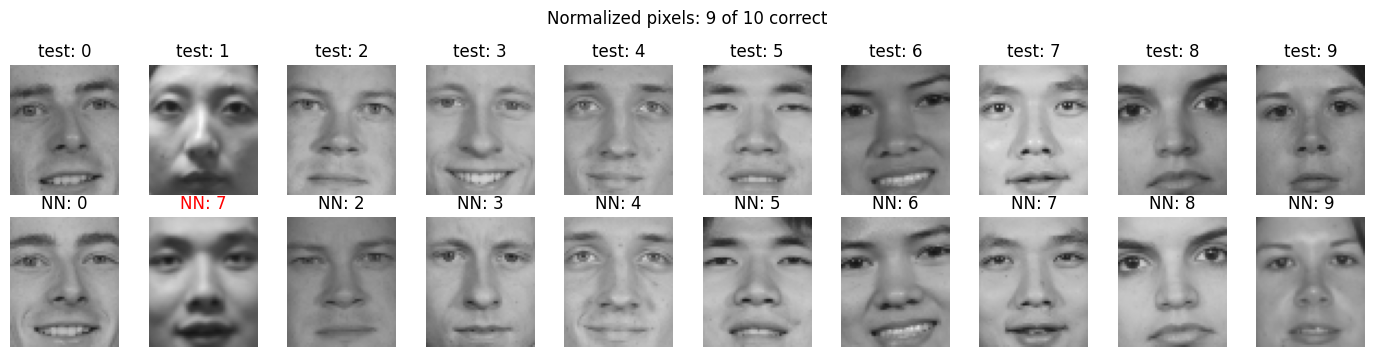

mean gray level: test face 0 131.8, raw NN (person 2) 125.0, normalized NN (person 0) 145.1


In [7]:
def normalize(vectors):
    return (vectors - vectors.mean(axis=1, keepdims=True)) / vectors.std(axis=1, keepdims=True)

train_norm = normalize(train_data)
test_norm = normalize(test_data)
show_matches(train_norm, test_norm, 'Normalized pixels')

# Test face 0: why raw pixels got it wrong
_, raw_best, _ = nearest_neighbor(train_data, train_labels, test_data[0])
_, norm_best, _ = nearest_neighbor(train_norm, train_labels, test_norm[0])
print(f'mean gray level: test face 0 {test_data[0].mean():.1f}, raw NN (person {train_labels[raw_best]}) '
      f'{train_data[raw_best].mean():.1f}, normalized NN (person {train_labels[norm_best]}) {train_data[norm_best].mean():.1f}')

For normalized vectors of $n$ entries, the squared Euclidean distance and the correlation $r$ are tied together exactly: $\lVert a - b \rVert^2 = 2n(1 - r)$. So the nearest normalized face is also the most correlated one, and correlation can be used as a distance.

In [8]:
n = train_norm.shape[1]
a, b = test_norm[3].astype(np.float64), train_norm[17].astype(np.float64)
r = np.dot(a, b) / n                       # correlation of two normalized vectors
print(f'squared distance {np.sum((a - b)**2):.2f}   2n(1 - r) = {2 * n * (1 - r):.2f}')

correlations = test_norm @ train_norm.T / n
print('most correlated face, same answers as the nearest one:',
      np.array_equal(train_labels[correlations.argmax(axis=1)],
                     [nearest_neighbor(train_norm, train_labels, q)[0] for q in test_norm]))

squared distance 1903.11   2n(1 - r) = 1903.11
most correlated face, same answers as the nearest one: True


## Nearest Neighbor on Eigenface Numbers

Instead of comparing 3,000 pixels, describe each face by its projections on the top $K$ eigenfaces of the training faces, as in the PCA lecture, and compare those $K$ numbers. The eigenfaces come from the 50 training faces only, so the test faces are new to them.

non-zero eigenvalues: 49 (50 faces span at most 49 directions)
K =  1: 2 of 10 correct
K =  2: 0 of 10 correct
K =  3: 3 of 10 correct
K =  5: 8 of 10 correct
K = 10: 9 of 10 correct
K = 20: 9 of 10 correct
K = 30: 9 of 10 correct
K = 49: 9 of 10 correct


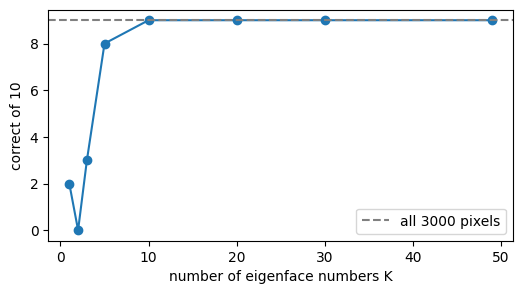

In [9]:
average_face = train_norm.mean(axis=0)
centered = train_norm - average_face
covariance = np.cov(centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = eigenvalues.argsort()[::-1]                  # eigh returns them smallest first
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
print('non-zero eigenvalues:', np.sum(eigenvalues > 1e-6 * eigenvalues[0]), '(50 faces span at most 49 directions)')

def pca_numbers(vectors, K):
    return (vectors - average_face) @ eigenvectors[:, :K]

results = {}
for K in [1, 2, 3, 5, 10, 20, 30, 49]:
    train_K, test_K = pca_numbers(train_norm, K), pca_numbers(test_norm, K)
    predicted = [nearest_neighbor(train_K, train_labels, q)[0] for q in test_K]
    results[K] = int(np.sum(np.array(predicted) == test_labels))
    print(f'K = {K:2d}: {results[K]} of 10 correct')

plt.figure(figsize=(6, 3))
plt.plot(list(results), list(results.values()), 'o-')
plt.axhline(9, color='gray', ls='--', label='all 3000 pixels')
plt.xlabel('number of eigenface numbers K'); plt.ylabel('correct of 10'); plt.legend()
plt.show()

With all 49 eigenfaces, the answers are exactly those of the raw pixels. The 50 training faces span only 49 directions around their mean, so keeping all 49 numbers changes no distance between training faces, and the part of a test face outside those directions adds the same amount to its distance from every training face.

In [10]:
same = all(nearest_neighbor(pca_numbers(train_norm, 49), train_labels, pca_numbers(test_norm[i:i+1], 49)[0])[1]
           == nearest_neighbor(train_norm, train_labels, test_norm[i])[1] for i in range(10))
print('K = 49 picks the same training face as raw pixels for every test face:', same)

K = 49 picks the same training face as raw pixels for every test face: True


## Two Model-Based Recognizers

Model-based recognition builds one model per person and asks which model fits a new face best.

1. **Average face and correlation**: each person's model is the average of their 5 photos; the best model is the one with the highest correlation, as in template matching.
2. **One PCA per person**: each person's model is the average and the top eigenfaces of their own photos; the best model is the one with the smallest reconstruction error, the `pca_score` of the PCA lecture.

In [11]:
people = range(10)
average_faces = normalize(np.array([train_norm[train_labels == c].mean(axis=0) for c in people]))
scores = test_norm @ average_faces.T / n                    # correlation with each average face
print('average face + correlation:', np.sum(scores.argmax(axis=1) == test_labels), 'of 10 correct')

def person_model(c, k):
    faces = train_norm[train_labels == c]
    mean = faces.mean(axis=0)
    # The top eigenvectors of this person's 3000 x 3000 covariance matrix. With only 5 faces,
    # np.linalg.svd of the 5 centered faces finds them far faster than eigh of the full matrix.
    _, _, vt = np.linalg.svd(faces - mean, full_matrices=False)
    return mean, vt[:k].T

def reconstruction_error(face, model):
    mean, vectors = model
    rebuilt = ((face - mean) @ vectors) @ vectors.T + mean
    return np.sum((face - rebuilt)**2)

for k in [1, 2, 3, 4]:
    models = [person_model(c, k) for c in people]
    predicted = [np.argmin([reconstruction_error(f, m) for m in models]) for f in test_norm]
    print(f'one PCA per person, {k} eigenfaces each:', np.sum(np.array(predicted) == test_labels), 'of 10 correct')

average face + correlation: 8 of 10 correct
one PCA per person, 1 eigenfaces each: 9 of 10 correct
one PCA per person, 2 eigenfaces each: 9 of 10 correct
one PCA per person, 3 eigenfaces each: 9 of 10 correct
one PCA per person, 4 eigenfaces each: 9 of 10 correct


## K Nearest Neighbors and a Vote

With K neighbors, each of the K closest training faces votes for its person. A tie goes to the tied person whose face is nearest. OpenCV has the same classifier as `cv.ml.KNearest`.

In [12]:
def knn(train_vectors, labels, query, K):
    distances = np.linalg.norm(train_vectors - query, axis=1)
    nearest = np.argsort(distances)[:K]
    votes = np.bincount(labels[nearest], minlength=10)
    tied = np.flatnonzero(votes == votes.max())
    for i in nearest:                     # nearest first: break ties by distance
        if labels[i] in tied:
            return labels[i]

for K in [1, 3, 5]:
    predicted = np.array([knn(train_norm, train_labels, q, K) for q in test_norm])
    print(f'K = {K}: {np.sum(predicted == test_labels)} of 10 correct, predictions {predicted}')

model = cv.ml.KNearest_create()
model.train(train_norm, cv.ml.ROW_SAMPLE, train_labels.astype(np.float32))
_, results_cv, neighbor_labels, neighbor_dists = model.findNearest(test_norm, k=1)
print('cv.ml.KNearest, k = 1:', results_cv.ravel().astype(int))

K = 1: 9 of 10 correct, predictions [0 7 2 3 4 5 6 7 8 9]
K = 3: 8 of 10 correct, predictions [0 7 2 3 4 5 6 7 8 2]
K = 5: 8 of 10 correct, predictions [7 0 2 3 4 5 6 7 8 9]
cv.ml.KNearest, k = 1: [0 7 2 3 4 5 6 7 8 9]


With only 5 photos per person, a larger K lets other people's photos outvote the right person. Test face 1 is wrong for every K: it is farther from all 5 of person 1's photos than from some photos of other people.

## Strangers and Thresholds

A nearest-neighbor matcher always returns somebody. To see what happens when the face belongs to nobody in the database, remove each person in turn and measure how far their test face is from the nearest remaining face. A threshold then decides: accept the match only if the distance is below it.

nearest photo of the same person:    [35.3 53.2 44.5 43.6 31.7 28.1 27.7 24.6 28.6 30.6]
nearest face when the person is gone: [44.2 35.7 45.5 51.7 39.5 43.  47.8 37.2 38.1 45.8]


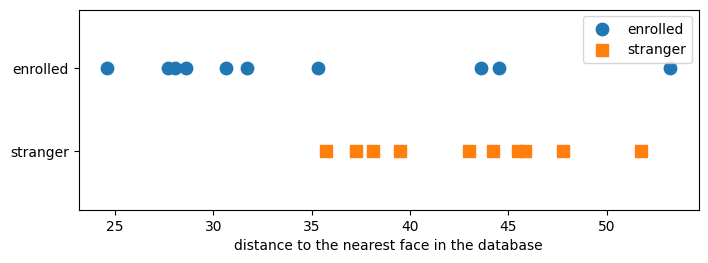

threshold 30: accepts  4 of 10 enrolled people and  0 of 10 strangers
threshold 33: accepts  6 of 10 enrolled people and  0 of 10 strangers
threshold 36: accepts  7 of 10 enrolled people and  1 of 10 strangers
threshold 40: accepts  7 of 10 enrolled people and  4 of 10 strangers
threshold 45: accepts  9 of 10 enrolled people and  6 of 10 strangers


In [13]:
D = np.linalg.norm(test_norm[:, None, :] - train_norm[None, :, :], axis=2)   # 10 x 50 distances
genuine = np.array([D[i][train_labels == test_labels[i]].min() for i in range(10)])
stranger = np.array([D[i][train_labels != test_labels[i]].min() for i in range(10)])
print('nearest photo of the same person:   ', genuine.round(1))
print('nearest face when the person is gone:', stranger.round(1))

plt.figure(figsize=(8, 2.6))
plt.scatter(genuine, np.ones(10), s=80, label='enrolled')
plt.scatter(stranger, np.zeros(10), s=80, marker='s', label='stranger')
plt.yticks([0, 1], ['stranger', 'enrolled']); plt.ylim(-0.7, 1.7)
plt.xlabel('distance to the nearest face in the database'); plt.legend(loc='upper right')
plt.show()

for threshold in [30, 33, 36, 40, 45]:
    print(f'threshold {threshold}: accepts {np.sum(genuine <= threshold):2d} of 10 enrolled people '
          f'and {np.sum(stranger <= threshold):2d} of 10 strangers')

No threshold separates the two rows completely. Raising it accepts more of the enrolled people and more strangers; lowering it rejects more of both. Which mistake is worse depends on the application: a phone should rarely accept a stranger, and a photo-tagging app can afford to.

## Searching Faster: Filter and Refine

With a large database, computing the full distance to every stored face is slow. **Filter**: compare the query with every face using only K PCA numbers, and keep the K' closest candidates. **Refine**: compute the full distance to those candidates only.

The 337 faces of the PCA lecture serve as the database, and each face in turn is the query (excluding itself).

In [14]:
faces = []
for filename in sorted(os.listdir('data/faces')):
    img = cv.imread('data/faces/' + filename, cv.IMREAD_GRAYSCALE)
    faces.append(img[25:85, 25:75].flatten())
faces = normalize(np.array(faces).astype(np.float32)).astype(np.float64)
mean_337 = faces.mean(axis=0)
values, vectors = np.linalg.eigh(np.cov(faces - mean_337, rowvar=False))
vectors = vectors[:, values.argsort()[::-1]]

K = 20
P = (faces - mean_337) @ vectors[:, :K]                       # 20 numbers per face

def all_distances(A):
    sq = np.sum(A**2, axis=1)
    return np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * A @ A.T, 0))

full = all_distances(faces); np.fill_diagonal(full, np.inf)
pca = all_distances(P);      np.fill_diagonal(pca, np.inf)
print('PCA distance never larger than the full distance:', np.all(pca <= full + 1e-6))

true_nn = full.argmin(axis=1)
for K_prime in [1, 5, 10, 20]:
    candidates = np.argsort(pca, axis=1)[:, :K_prime]
    missed = sum(true_nn[q] not in candidates[q] for q in range(len(faces)))
    print(f"K' = {K_prime:2d}: the true nearest face is missed for {missed} of {len(faces)} queries")

PCA distance never larger than the full distance: True
K' =  1: the true nearest face is missed for 144 of 337 queries
K' =  5: the true nearest face is missed for 17 of 337 queries
K' = 10: the true nearest face is missed for 0 of 337 queries
K' = 20: the true nearest face is missed for 0 of 337 queries


Because the PCA distance is never larger than the full distance, the search can also be made **exact**: go through the candidates in order of PCA distance, and stop as soon as the next PCA distance is larger than the best full distance found so far. No face further down the list can be closer.

In [15]:
def exact_search(q):
    best, best_index, computed = np.inf, -1, 0
    for j in np.argsort(pca[q])[:-1]:            # all other faces, closest in PCA numbers first
        if pca[q][j] >= best:
            break                                 # nothing further down can beat `best`
        computed += 1
        if full[q][j] < best:
            best, best_index = full[q][j], j
    return best_index, computed

found, work = zip(*[exact_search(q) for q in range(len(faces))])
print('exact search finds the true nearest face every time:', np.array_equal(found, true_nn))
print(f'full distances computed per query: {np.mean(work):.1f} on average (at most {max(work)}), instead of {len(faces) - 1}')

exact search finds the true nearest face every time: True
full distances computed per query: 48.0 on average (at most 185), instead of 336


## Image Moments by Hand

A raw moment $M_{ij} = \sum_x \sum_y x^i y^j I(x, y)$ weights every pixel by its position. Here $x$ is the **column** and $y$ the **row**, the convention of `cv.moments`. Getting it backwards swaps the two coordinates of the centroid.

The loop converts each pixel to `float` before multiplying: a `uint8` pixel times a Python integer stays `uint8` in NumPy 2 and overflows past 255.

In [16]:
def raw_moment_loop(image, i, j):
    rows, cols = image.shape
    M = 0.0
    for y in range(rows):          # y: the row
        for x in range(cols):      # x: the column
            M += (x**i) * (y**j) * float(image[y, x])
    return M

def raw_moment(image, i, j):
    y, x = np.mgrid[:image.shape[0], :image.shape[1]]  # row, column
    return np.sum((x**i) * (y**j) * image.astype(np.float64))

# A white rectangle on black: columns 150 to 189, rows 10 to 29
rect = np.zeros((100, 200), np.uint8)
cv.rectangle(rect, (150, 10), (189, 29), 1, -1)

m = cv.moments(rect, binaryImage=True)
print('area M00:          ', raw_moment(rect, 0, 0), raw_moment_loop(rect, 0, 0), m['m00'])
print('centroid column x: ', raw_moment(rect, 1, 0) / raw_moment(rect, 0, 0), m['m10'] / m['m00'])
print('centroid row y:    ', raw_moment(rect, 0, 1) / raw_moment(rect, 0, 0), m['m01'] / m['m00'])

t0 = time.perf_counter(); raw_moment_loop(rect, 2, 1); t1 = time.perf_counter(); raw_moment(rect, 2, 1); t2 = time.perf_counter()
print(f'loop {1000 * (t1 - t0):.1f} ms, vectorized {1000 * (t2 - t1):.2f} ms')

area M00:           800.0 800.0 800.0
centroid column x:  169.5 169.5
centroid row y:     19.5 19.5
loop 4.8 ms, vectorized 0.25 ms


In [17]:
# What the uint8 overflow does to a loop without float()
img = np.full((5, 5), 200, np.uint8)
M = 0
with np.errstate(over='ignore'):
    for y in range(5):
        for x in range(5):
            M += (x**2) * (y**1) * img[y, x]
print('M21 without float():', M, '  with float():', raw_moment_loop(img, 2, 1))

M21 without float(): 96   with float(): 60000.0


## Central, Normalized and Hu Moments

The same circle-with-a-bar shape as on the slides, drawn four ways: as is, moved, twice as large, and twice as large and turned. The table shows which numbers change.

- `m10`, a raw moment, changes when the shape moves.
- `mu20`, a central moment, ignores the move but grows with the size.
- `nu20`, a normalized central moment, ignores move and size (up to the pixel grid) but not the turn.
- `hu1`, the first Hu moment, ignores all three.

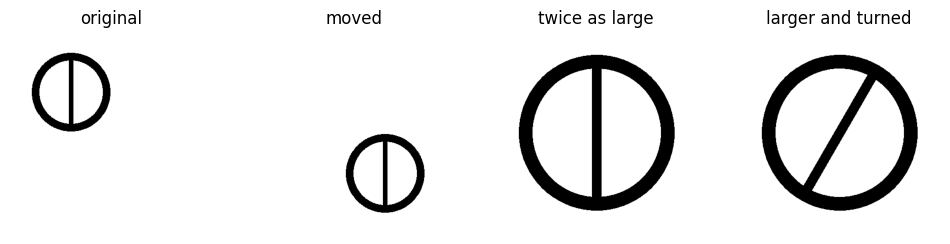

                             m10          mu20     nu20      hu1
original                  927674      16349351   0.2738   0.5721
moved                    2009594      16349351   0.2738   0.5721
twice as large           5705356     234433808   0.2881   0.6075
larger and turned        5721863     240917806   0.2944   0.6045


In [18]:
def ring(size, center, radius, bar_angle=90):
    img = np.zeros((size, size), np.uint8)
    cv.circle(img, center, radius, 1, max(2, round(radius * 0.18)))
    a = np.deg2rad(bar_angle)
    d = np.array([np.cos(a), -np.sin(a)]) * radius
    p1 = tuple(int(round(v)) for v in np.array(center) + d)
    p2 = tuple(int(round(v)) for v in np.array(center) - d)
    cv.line(img, p1, p2, 1, max(2, round(radius * 0.12)))
    return img

shapes = {'original': ring(400, (120, 120), 70),
          'moved': ring(400, (260, 280), 70),
          'twice as large': ring(400, (200, 200), 140),
          'larger and turned': ring(400, (200, 200), 140, bar_angle=60)}

fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for ax, (name, img) in zip(axs, shapes.items()):
    ax.imshow(img, cmap='gray_r'); ax.set_title(name); ax.axis('off')
plt.show()

print(f"{'':20s}{'m10':>12s}{'mu20':>14s}{'nu20':>9s}{'hu1':>9s}")
for name, img in shapes.items():
    m = cv.moments(img, binaryImage=True)
    hu = cv.HuMoments(m).flatten()
    print(f"{name:20s}{m['m10']:12.0f}{m['mu20']:14.0f}{m['nu20']:9.4f}{hu[0]:9.4f}")

**Another trap: the intensity scale.** Normalized central moments, and therefore Hu moments, depend on whether the shape is stored as 1 or as 255. With `binaryImage=True`, `cv.moments` treats every non-zero pixel as 1.

In [19]:
img255 = shapes['original'] * 255
print('hu1 with the shape stored as 255:     ', cv.HuMoments(cv.moments(img255)).flatten()[0])
print('hu1 with binaryImage=True:            ', cv.HuMoments(cv.moments(img255, binaryImage=True)).flatten()[0])

hu1 with the shape stored as 255:      0.0022434000172373136
hu1 with binaryImage=True:             0.5720670043955147


## Recognizing Digits With Hu Moments

`draw_digit` writes a digit with one of OpenCV's Hershey fonts and turns it about the image center. `make_digits` draws every digit in 4 fonts, 8 times each, at random sizes and angles: half for training, half for testing. Each image becomes a vector of its 7 Hu moments, and a test digit gets the label of its nearest training digit.

320 digits: 160 for training, 160 for testing


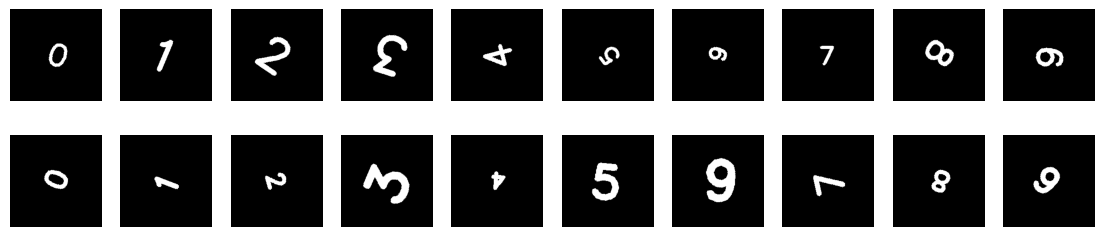

In [20]:
FONTS = [cv.FONT_HERSHEY_SIMPLEX, cv.FONT_HERSHEY_DUPLEX, cv.FONT_HERSHEY_COMPLEX, cv.FONT_HERSHEY_TRIPLEX]

def draw_digit(ch, font=cv.FONT_HERSHEY_SIMPLEX, scale=3.0, angle=0.0, size=200):
    """A white digit on black, drawn with an OpenCV Hershey font, then rotated about the image center."""
    img = np.zeros((size, size), np.uint8)
    thickness = max(2, round(3 * scale))
    (w, h), _ = cv.getTextSize(ch, font, scale, thickness)
    cv.putText(img, ch, ((size - w) // 2, (size + h) // 2), font, scale, 255, thickness, cv.LINE_8)
    M = cv.getRotationMatrix2D((size / 2, size / 2), angle, 1.0)
    return cv.warpAffine(img, M, (size, size), flags=cv.INTER_NEAREST)

def make_digits(per_font=8, seed=12):
    """Every digit in every font, per_font times at a random scale and rotation; half for training, half for testing."""
    rng = np.random.default_rng(seed)
    images, labels, train_mask = [], [], []
    for d in range(10):
        for font in FONTS:
            for k in range(per_font):
                images.append(draw_digit(str(d), font, rng.uniform(1.5, 4.0), rng.uniform(-180, 180)))
                labels.append(d)
                train_mask.append(k % 2 == 0)
    return np.array(images), np.array(labels), np.array(train_mask)

digit_images, digit_labels, is_train = make_digits()
print(len(digit_images), 'digits:', is_train.sum(), 'for training,', (~is_train).sum(), 'for testing')

fig, axs = plt.subplots(2, 10, figsize=(14, 3))
for d in range(10):
    for row in range(2):
        axs[row, d].imshow(digit_images[digit_labels == d][row * 9], cmap='gray'); axs[row, d].axis('off')
plt.show()

In [21]:
def hu(img):
    return cv.HuMoments(cv.moments(img, binaryImage=True)).flatten()

def log_hu(h):
    return -np.sign(h) * np.log10(np.abs(h))

H = np.array([hu(img) for img in digit_images])
print('Hu moments of the first digit:          ', H[0])
print('the same on a log scale:                ', log_hu(H[0]).round(2))

def classify(features):
    train_f, test_f = features[is_train], features[~is_train]
    D = np.linalg.norm(test_f[:, None, :] - train_f[None, :, :], axis=2)
    return digit_labels[is_train][D.argmin(axis=1)]

test_true = digit_labels[~is_train]
for name, features in [('plain Hu moments', H), ('log-scaled Hu moments', log_hu(H))]:
    predicted = classify(features)
    print(f'{name:22s}: {np.mean(predicted == test_true):.0%} correct')

Hu moments of the first digit:           [4.37914596e-01 1.64440926e-02 1.29768421e-06 2.47561761e-06
 1.68117989e-12 5.18513706e-08 4.10639199e-12]
the same on a log scale:                 [ 0.36  1.78  5.89  5.61 11.77  7.29 11.39]
plain Hu moments      : 60% correct
log-scaled Hu moments : 85% correct


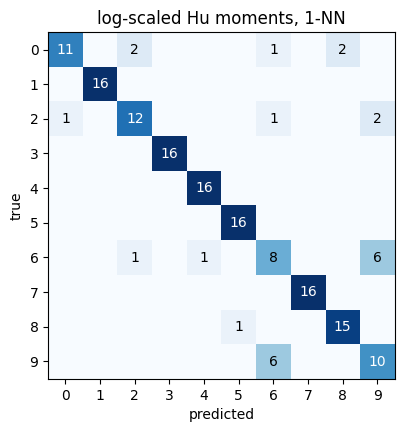

24 mistakes, 12 of them between 6 and 9


In [22]:
predicted = classify(log_hu(H))
confusion = np.zeros((10, 10), int)
for t, p in zip(test_true, predicted):
    confusion[t, p] += 1
plt.figure(figsize=(5.5, 4.5))
plt.imshow(confusion, cmap='Blues')
for t in range(10):
    for p in range(10):
        if confusion[t, p]:
            plt.text(p, t, confusion[t, p], ha='center', va='center', color='white' if confusion[t, p] > 8 else 'black')
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel('predicted'); plt.ylabel('true')
plt.title('log-scaled Hu moments, 1-NN')
plt.show()
wrong = int(np.sum(predicted != test_true))
print(f'{wrong} mistakes, {confusion[6, 9] + confusion[9, 6]} of them between 6 and 9')

**When invariance hurts.** In this font a 9 is a 6 turned upside down, so their Hu moments are equal and no distance on them can tell the two apart. `cv.matchShapes` compares two shapes by their log-scaled Hu moments and returns 0 for a perfect match. Mirroring a shape changes only the sign of the seventh Hu moment.

In [23]:
six, nine, three, eight = draw_digit('6'), draw_digit('9'), draw_digit('3'), draw_digit('8')
print('log Hu, 6:', log_hu(hu(six)).round(2))
print('log Hu, 9:', log_hu(hu(nine)).round(2))
print('matchShapes(6, 9):', cv.matchShapes(six, nine, cv.CONTOURS_MATCH_I1, 0))
print('matchShapes(3, 8):', cv.matchShapes(three, eight, cv.CONTOURS_MATCH_I1, 0))
print('log Hu, 3:         ', log_hu(hu(three)).round(2))
print('log Hu, mirrored 3:', log_hu(hu(cv.flip(three, 1))).round(2))

log Hu, 6: [ 0.51  1.88  3.27  4.02 -8.05 -4.99  7.7 ]
log Hu, 9: [ 0.51  1.88  3.27  4.02 -8.05 -4.99  7.7 ]
matchShapes(6, 9): 5.551115123125783e-17
matchShapes(3, 8): 0.020682198625820603
log Hu, 3:          [ 0.35  1.22  2.13  2.74 -5.71 -3.42 -5.2 ]
log Hu, mirrored 3: [ 0.35  1.22  2.13  2.74 -5.71 -3.42  5.2 ]


## Try It Yourself

1. In the face section, use the L1 distance (`np.sum(np.abs(...))`) instead of the Euclidean distance. Does anything change, with and without normalization?
2. Test face 1 is the one nearly every method gets wrong. Show its 5 nearest training faces with their distances. Why is it hard?
3. In the strangers section, which threshold accepts all 10 enrolled people, and how many strangers does it let in?
4. Change `K` in the filter-and-refine section to 5 and to 50. How do the misses and the number of full distances change?
5. Explain why no feature that ignores rotation can tell this font's 6 from its 9. Then build a digit set whose angles stay between -30 and 30 degrees (change the `rng.uniform(-180, 180)` in `make_digits`), add the normalized central moments `nu20`, `nu11`, `nu02`, `nu30`, `nu21`, `nu12` and `nu03` to each feature vector, and check whether the 6/9 confusion goes away.
6. Classify the digits with `cv.matchShapes` as the distance instead of the Euclidean distance on log-scaled Hu moments. Is it better or worse?